# 03 &nbsp;How often are the answers right?

Notebook 02 measured whether each configuration puts the right text in front of the model. This one measures what the model does with it: Gemma 4 E4B answered 150 MultiHop-RAG questions and 100 Natural Questions with each of the 24 answer configurations, and with no documents at all. Accuracy is the share of answerable questions answered correctly.

Comparisons are paired by question, with 95% bootstrap intervals over questions.

In [1]:
import warnings

warnings.filterwarnings("ignore", message="urllib3 v2 only supports OpenSSL")  # old SSL on macOS system Python

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ragdecisions import style
from ragdecisions.data import DATASETS, RESULTS_DIR, load_questions
from ragdecisions.grid import ANSWER_CHUNK_SIZES, ANSWER_RETRIEVERS
from ragdecisions.stats import bootstrap_means, interval

style.use_style()
HAND_CHECK = RESULTS_DIR / "hand_check.csv"


def load(dataset):
    answers = pd.read_csv(RESULTS_DIR / f"answers_{dataset}.csv", keep_default_na=False, na_values=[""])
    grades = pd.read_csv(RESULTS_DIR / f"grades_{dataset}.csv", keep_default_na=False, na_values=[""])
    table = answers.merge(grades[["qid", "answer", "correct", "method"]], on=["qid", "answer"], how="left")
    table["correct"] = table["correct"].astype(str).eq("True").astype(float)
    questions = load_questions(dataset).set_index("qid")
    table["answerable"] = table["qid"].map(questions["type"]) != "null"
    return table, grades


tables, grades = {}, {}
for name in DATASETS:
    tables[name], grades[name] = load(name)
    t = tables[name]
    print(f"{DATASETS[name]}: {len(t):,} answers to {t['qid'].nunique()} questions, "
          f"{t[t['answerable']]['qid'].nunique()} of them answerable")

MultiHop-RAG: 3,750 answers to 150 questions, 133 of them answerable
Natural Questions: 2,500 answers to 100 questions, 100 of them answerable


## 1. How the answers were graded

Each configuration often gives the same answer to a question, so every distinct answer to a question is graded once. A matching rule decides the clear cases: a question the articles cannot answer is right only if the model declines, declining an answerable question is wrong, an answer equal to a reference after normalizing is right, and for Yes or No questions the first word decides. A local Gemma 4 12B judge, comparing the answer with the reference answers only, decides the rest.

In [2]:
routes = pd.DataFrame({
    DATASETS[name]: {
        "Distinct answers": len(g),
        "Decided by the rule": int((g["method"] == "rule").sum()),
        "Decided by the judge": int((g["method"] == "judge").sum()),
        "Judge replies that could not be read": int(g["correct"].isna().sum()),
    }
    for name, g in grades.items()
})
routes

,MultiHop-RAG,Natural Questions
Distinct answers,367,497
Decided by the rule,342,186
Decided by the judge,25,311
Judge replies that could not be read,0,0


To check the grading, 100 distinct MultiHop-RAG answers and 50 Natural Questions answers were labelled. On MultiHop-RAG that is every answer the judge decided plus a random sample of the rest; on Natural Questions, a random 35 of the judge's and 15 of the rule's. Labels were drafted without seeing the automatic grade, then reviewed by hand against the references and the evidence; the review changed one label. Weighting each route by the share of all answers it decides gives the expected agreement over every answer.

In [3]:
check = pd.read_csv(HAND_CHECK, keep_default_na=False)
check = check.merge(pd.concat(grades.values()), on=["dataset", "qid", "answer"])
check["automatic"] = np.where(check["correct"].astype(str) == "True", "right", "wrong")
check["agree"] = check["automatic"] == check["label"]
agreement = check.groupby(["dataset", "route"]).agg(checked=("agree", "size"), agree=("agree", "sum"))
share = {name: t["method"].value_counts(normalize=True) for name, t in tables.items()}
agreement["share of all answers"] = [share[d][r] for d, r in agreement.index]
agreement["agreement"] = agreement["agree"] / agreement["checked"]
expected = (agreement["share of all answers"] * agreement["agreement"]).groupby(level="dataset").sum()
agreement.index = agreement.index.set_levels([DATASETS[d] for d in agreement.index.levels[0]], level=0)
for name, value in expected.items():
    print(f"{DATASETS[name]}: expected agreement with a person over all answers {value:.1%}")
agreement.style.format({"share of all answers": "{:.0%}", "agreement": "{:.0%}"})

MultiHop-RAG: expected agreement with a person over all answers 99.8%
Natural Questions: expected agreement with a person over all answers 94.1%


On MultiHop-RAG the rule agrees with the hand labels on all 75 checked answers and the judge on 24 of 25. Its one miss is the answer "Align" to a question asking whether two articles align or portray ChatGPT as lacking: the reference "no" answers the second part, so "Align" is right, and the judge marked it wrong. Because the judge decides only 3.8% of MultiHop-RAG answers, about 99.8% of those grades should match a person. On Natural Questions the rule agrees on all 15, but the judge on 30 of 35: it accepted two answers that do not match any reference, rejected two that give two of several accepted names, and accepted a list of every Rolling Stone, past and present. Because the judge decides 41% of Natural Questions answers, about 94% of those grades should match a person. The errors go both ways and every configuration is graded the same way, so they add noise to the comparisons rather than favouring one configuration; the judge prompt was not changed after this check.

## 2. The floor: the same model with no documents

In [4]:
floor = {}
for name, t in tables.items():
    a = t[t["answerable"]]
    floor[name] = a[a["k"] == 0]["correct"].mean()
    best = a[a["k"] > 0].groupby(["chunk", "retriever", "rerank", "k"])["correct"].mean()
    print(f"{DATASETS[name]}: {floor[name]:.0%} with no documents, {best.max():.0%} for the best configuration "
          f"({best.min():.0%} for the worst)")
mhr = tables["multihop_rag"]
unanswerable = mhr[~mhr["answerable"] & (mhr["k"] > 0)]
print(f"MultiHop-RAG questions the articles cannot answer, answered anyway with documents: "
      f"{1 - unanswerable['correct'].mean():.1%}")

types = load_questions("multihop_rag").set_index("qid")["type"]
by_type = mhr[mhr["answerable"]].assign(type=lambda t: t["qid"].map(types))
by_type = by_type.assign(setting=np.where(by_type["k"] == 0, "no documents", "with documents, average"))
by_type.groupby(["type", "setting"])["correct"].mean().unstack().style.format("{:.0%}")

MultiHop-RAG: 38% with no documents, 71% for the best configuration (30% for the worst)
Natural Questions: 20% with no documents, 70% for the best configuration (34% for the worst)
MultiHop-RAG questions the articles cannot answer, answered anyway with documents: 0.0%


setting,no documents,"with documents, average"
type,,
comparison,12%,52%
inference,62%,66%
temporal,41%,32%


With no documents the model already gets 38% of MultiHop-RAG right, for two reasons. Inference questions ask about well-known people and companies (Sam Bankman-Fried, Google, ChatGPT), and the model names them from what it learned in training: 62% right with no documents. Temporal questions go the other way: 41% right with no documents and 32% with them, while the model declines about half of them either way. So a weak configuration can score below no documents at all; notebook 04 looks at why.

Comparison questions are where the documents matter most: with none, the model declines most of them, and accuracy rises from 12% to 52% with documents. And with documents in the prompt, the model never answered a question the articles cannot answer.

## 3. Accuracy for every configuration

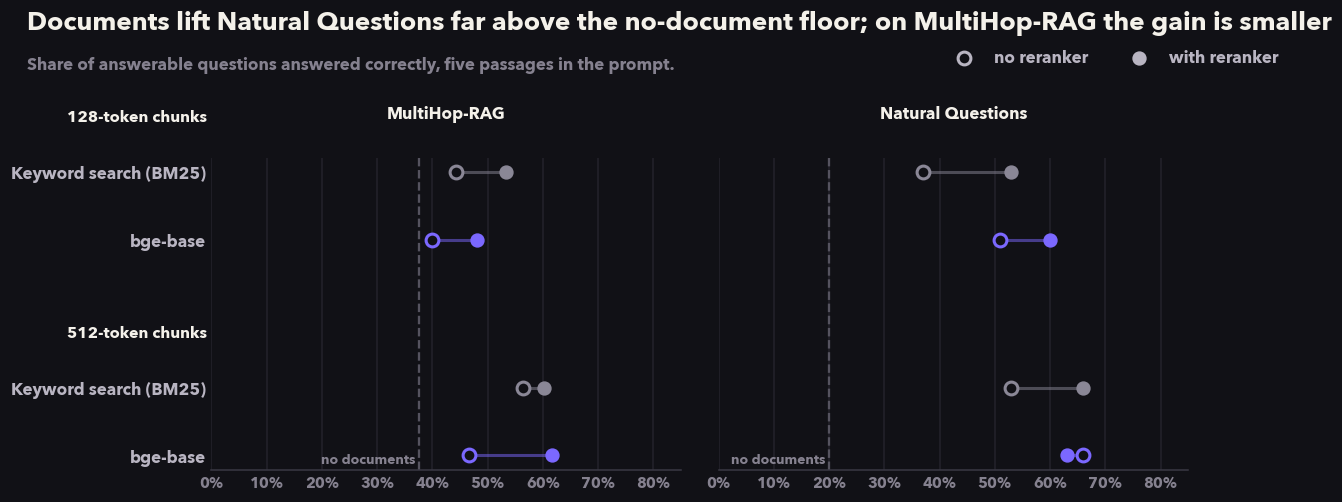

In [5]:
def dot_plot(table, k, ax, title, group_labels=True):
    # One row per retriever and chunk size: hollow without the reranker, filled with it.
    means = table[table["answerable"] & (table["k"] == k)].groupby(["chunk", "retriever", "rerank"])["correct"].mean()
    y, ticks, labels = 0, [], []
    for size in ANSWER_CHUNK_SIZES:
        if group_labels:
            ax.text(-0.01, y - 0.75, f"{size}-token chunks", transform=ax.get_yaxis_transform(), ha="right",
                    color=style.INK, fontsize=10.5, fontweight="bold")
        for key in ANSWER_RETRIEVERS:
            off, on = means[size, key, False], means[size, key, True]
            color = style.RETRIEVER_COLORS[key]
            ax.plot([off, on], [y, y], color=color, lw=2, alpha=0.5, zorder=2)
            ax.scatter(off, y, s=70, facecolor=style.SURFACE, edgecolor=color, lw=2, zorder=3)
            ax.scatter(on, y, s=70, color=color, zorder=3)
            ticks.append(y)
            labels.append(style.RETRIEVER_LABELS[key])
            y += 1
        y += 1.2
    ax.set_yticks(ticks, labels)
    ax.invert_yaxis()
    ax.set_xlim(0, 0.85)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_title(title, color=style.INK, fontsize=11, pad=26)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)
for ax, name in zip(axes, DATASETS):
    dot_plot(tables[name], 5, ax, DATASETS[name], group_labels=name == "multihop_rag")
    ax.axvline(floor[name], color=style.FLOOR_COLOR, lw=1.5, ls="--")
    ax.text(floor[name], 0.02, "no documents ", transform=ax.get_xaxis_transform(), color=style.MUTED, fontsize=9, ha="right")
axes[1].tick_params(labelleft=False)
axes[0].scatter([], [], s=70, facecolor=style.SURFACE, edgecolor=style.INK_2, lw=2, label="no reranker")
axes[0].scatter([], [], s=70, color=style.INK_2, label="with reranker")
fig.legend(loc="upper right", bbox_to_anchor=(0.98, 0.935), ncol=2)
style.headline(fig, "Documents lift Natural Questions far above the no-document floor; on MultiHop-RAG the gain is smaller",
               "Share of answerable questions answered correctly, five passages in the prompt.")
fig.subplots_adjust(top=0.7, left=0.16, wspace=0.08)
style.save(fig, "accuracy_by_configuration")
plt.show()

## 4. Each choice, averaged over all the others

In [6]:
CONTRASTS = [
    ("Add the reranker", "rerank", True, False),
    ("bge-base instead of keyword search", "retriever", "bge-base", "bm25"),
    ("512-token chunks instead of 128", "chunk", 512, 128),
    ("10 passages instead of 3", "k", 10, 3),
    ("5 passages instead of 3", "k", 5, 3),
]


def contrast(table, column, a, b):
    grid = table[table["answerable"] & (table["k"] > 0)]
    if column == "k":
        grid = grid[grid["k"].isin([a, b])]
    per_question = grid.groupby(["qid", column])["correct"].mean().unstack(column)
    diff = (per_question[a] - per_question[b]).to_numpy()
    low, high = interval(bootstrap_means(diff, seed=0)[:, 0])
    return {"difference": diff.mean(), "low": low, "high": high}


effects = {name: pd.DataFrame({label: contrast(tables[name], col, a, b) for label, col, a, b in CONTRASTS}).T
           for name in DATASETS}


def points(x):
    x = round(x * 100, 1)
    return "0.0" if x == 0 else f"{x:+.1f}"


summary = pd.DataFrame({
    DATASETS[name]: e.apply(lambda r: f"{points(r['difference'])} ({points(r['low'])} to {points(r['high'])})", axis=1)
    for name, e in effects.items()
})
summary

,MultiHop-RAG,Natural Questions
Add the reranker,+8.6 (+4.9 to +12.7),+6.1 (+2.8 to +9.6)
bge-base instead of keyword search,-2.5 (-6.2 to +1.0),+7.9 (+2.6 to +13.6)
512-token chunks instead of 128,+10.3 (+6.2 to +14.8),+12.2 (+7.6 to +17.5)
10 passages instead of 3,+19.9 (+16.2 to +23.6),+7.5 (+4.5 to +10.9)
5 passages instead of 3,+9.2 (+6.9 to +11.6),+4.4 (+1.9 to +7.1)


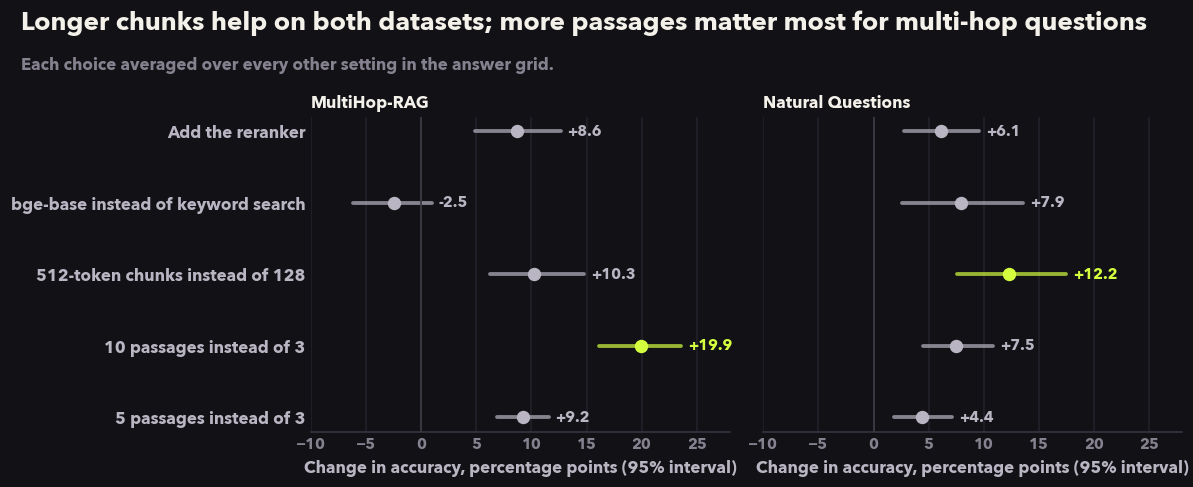

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, name in zip(axes, DATASETS):
    rows = effects[name].iloc[::-1]
    best = rows["difference"].abs().idxmax()
    for i, (label, r) in enumerate(rows.iterrows()):
        color = style.HIGHLIGHT if label == best else style.INK_2
        ax.plot([r["low"] * 100, r["high"] * 100], [i, i], color=color, lw=2.5, alpha=0.7)
        ax.scatter(r["difference"] * 100, i, color=color, s=60, zorder=3)
        ax.text(r["high"] * 100 + 0.6, i, points(r["difference"]), va="center", color=color, fontsize=10)
    ax.axvline(0, color=style.BASELINE, lw=1.2)
    ax.set_yticks(np.arange(len(rows)), rows.index)
    ax.set_xlim(-10, 28)
    ax.set_title(DATASETS[name], loc="left", color=style.INK, fontsize=11)
    ax.set_xlabel("Change in accuracy, percentage points (95% interval)")
style.headline(fig, "Longer chunks help on both datasets; more passages matter most for multi-hop questions",
               "Each choice averaged over every other setting in the answer grid.")
fig.subplots_adjust(top=0.76, left=0.24, wspace=0.08)
style.save(fig, "accuracy_effects")
plt.show()

## What this tells us

- **Retrieval pays off, but not everywhere.** The best configuration answers 71% of MultiHop-RAG questions and 70% of Natural Questions correctly, against 38% and 20% with no documents. On MultiHop-RAG the worst configuration, at 30%, does worse than no documents.
- **Answers follow the retrieval pattern.** On MultiHop-RAG, bge-base and keyword search cannot be told apart (bge-base 2.5 points lower, interval from 6.2 lower to 1.0 higher). On Natural Questions, bge-base is 7.9 points better.
- **The reranker helps on both datasets:** 8.6 points on MultiHop-RAG and 6.1 on Natural Questions. On Natural Questions that is more than the 2.1 points of evidence it added in notebook 02; notebook 04 asks why.
- **More text in the prompt helps most.** 512-token chunks instead of 128 add 10.3 and 12.2 points. Ten passages instead of three add 19.9 points on MultiHop-RAG, where answers need several articles, but 7.5 on Natural Questions, where they need one.
- **The model does not invent answers to unanswerable questions:** with documents, it declined every MultiHop-RAG question the articles cannot answer.

All of these come at a price in prompt length or extra model calls, which notebook 05 puts in dollars.

Next: [notebook 04](04_retrieval_vs_answers.ipynb) asks whether the retrieval scores from notebook 02 predict these answers.